In [2]:
%load_ext autoreload
%autoreload 2
from notebook_cache import NotebookCache

cache = NotebookCache('../cache/dreamzero')

# DreamZero, small, built from scratch on T1

DreamZero = a pretrained **video** model (Wan, 14B) taught to also output **actions**: one transformer denoises the next frames and the next actions together. Here everything is ours and tiny, and the video model learns only T1.

The bet: video is cheap, labels are not. Does a video model pretrained on lots of T1 video make actions learnable from few labelled demos?

```-
stage               trains on                               learns
1  video model      80 demos, frames only                   what happens next in T1   (our "Wan")
2  world-action     10 labelled demos, frames + actions     actions, on top of stage 1
baseline            stage 2 alone, from random weights      (uwm2: 10 labelled -> 30/40)
```

DreamZero's recipe (paper sec. 3.1, app. C): a demo is cut into **chunks** (K frames + the H actions that span them). Chunk k is noised to one level τ_k shared by its frames and actions, and denoised while seeing the **clean** chunks before it (teacher forcing). In the sim, the real frames replace the dreamed ones after each chunk is played.

### step 0 — the data: 100 demos, uwm2's split


In [3]:
import numpy as np
from frozendict import frozendict
from uwm_parts import load_table, load_top

NAME = 'pick_place_cube_n100'

In [4]:
@cache
def table():
    return load_table(NAME)  # state [N, 8], action [N, 8], episode [N]

table: cached, 1 call(s) stored


In [5]:
@cache
def images():
    return load_top(NAME)  # [N, 3, 128, 128] uint8, top camera, a few minutes the first time

images: cached, 1 call(s) stored


In [6]:
def split():
    # episode ids, as uwm2: 10 held out, 10 labelled, the other 80 frames only
    val = np.random.default_rng(0).permutation(100)[:10]
    train = np.setdiff1d(np.arange(100), val)
    labelled = np.random.default_rng(1).choice(train, 10, replace=False)
    return frozendict(val=val, labelled=labelled, video=np.setdiff1d(train, labelled))


state, action, episode = table()
top = images()
eps = split()
print(f'{top.shape=}  demo length {np.bincount(episode).min()}..{np.bincount(episode).max()} steps')
print({k: len(v) for k, v in eps.items()})

top.shape=(21295, 3, 128, 128)  demo length 197..237 steps
{'val': 10, 'labelled': 10, 'video': 80}


### step 1 — a demo cut into chunks

A sample = the frame now, then M = 4 chunks. Chunk k = the H = 16 actions it plays and the K = 2 frames they lead through (one every 8 steps). Training will denoise chunk k while it sees the clean chunks before it.


In [7]:
K, H, M = 2, 16, 4  # frames per chunk, actions per chunk, chunks per sample


def chunks_of(e: int, start: int):
    # rows of demo e from step `start`: the frame now, then M chunks of K frames + H actions
    now = np.flatnonzero(episode == e)[0] + start
    return frozendict(
        now=now,
        frames=now + H // K * np.arange(1, M * K + 1).reshape(M, K),  # [M, K], every 8 steps
        acts=now + np.arange(M * H).reshape(M, H),  # [M, H]
    )


ex = chunks_of(int(eps['labelled'][0]), start=40)
print(f'now {ex["now"]}\nframes\n{ex["frames"]}\nactions first/last\n{ex["acts"][:, [0, -1]]}')

now 6631
frames
[[6639 6647]
 [6655 6663]
 [6671 6679]
 [6687 6695]]
actions first/last
[[6631 6646]
 [6647 6662]
 [6663 6678]
 [6679 6694]]


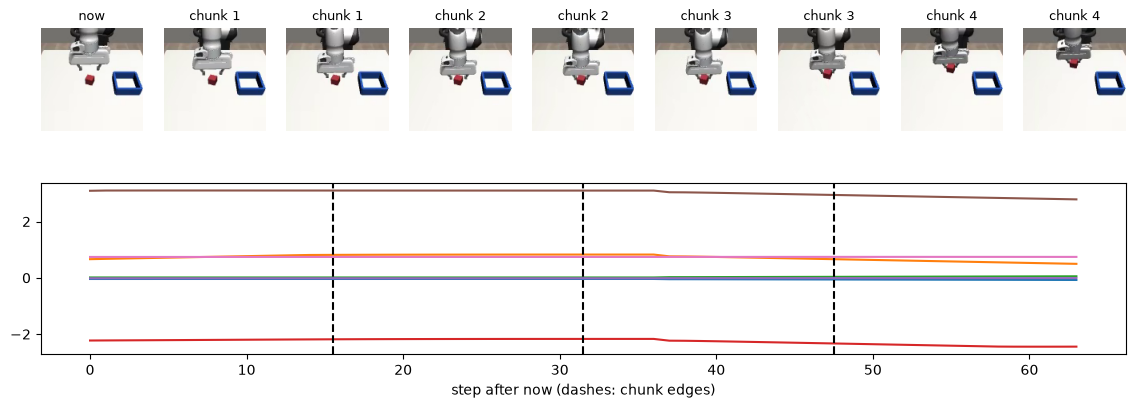

In [8]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(14, 4.5))
grid = fig.add_gridspec(2, 1 + M * K, height_ratios=[1, 1.2])
rows = [ex['now']] + list(ex['frames'].flatten())
for i, row in enumerate(rows):
    ax = fig.add_subplot(grid[0, i])
    ax.imshow(np.transpose(top[row], (1, 2, 0)))
    ax.set_title('now' if i == 0 else f'chunk {(i - 1) // K + 1}', fontsize=9)
    ax.axis('off')
ax = fig.add_subplot(grid[1, :])
ax.plot(action[ex['acts'].flatten(), :7])  # the 7 arm joints, 64 steps
for k in range(1, M):
    ax.axvline(k * H - 0.5, color='k', ls='--')
ax.set_xlabel('step after now (dashes: chunk edges)')
plt.show()

### step 2 — a batch: many samples at random demos and moments

Everything on the GPU once (~1 GB of frames). Each sample: the 9 frames (now + 4 chunks × 2), the 4 × 16 actions, and the joints at the start of each chunk (DreamZero's state input, q_k).


In [9]:
from dataclasses import dataclass

import torch
from torch import Tensor

dev = 'cuda'
gpu = frozendict(
    top=torch.tensor(top, device=dev),  # [N, 3, 128, 128] uint8
    state=torch.tensor(state, device=dev),  # [N, 8]
    action=torch.tensor(action, device=dev),  # [N, 8]
)


@dataclass(frozen=True, kw_only=True)
class Batch:
    frames: Tensor  # [B, 9, 3, 128, 128] uint8: now, then every 8 steps
    rows: Tensor  # [B, 9] those frames' rows, to look up anything else stored per frame
    acts: Tensor  # [B, M, H, 8]
    state: Tensor  # [B, M, 8], at each chunk's first step


def get_batch(ids: np.ndarray, B: int, rng: np.random.Generator, to_end: bool = False):
    # B samples from demos `ids`, each at a random moment with room for M chunks after it;
    # to_end: the moment can be any step, rows past the demo's end repeat its last one
    first, lens = np.searchsorted(episode, np.arange(100)), np.bincount(episode)
    e = rng.choice(ids, B)
    last = (first[e] + lens[e] - 1)[:, None]  # [B, 1]
    now = first[e] + rng.integers(0, lens[e] if to_end else lens[e] - M * H)  # [B]
    frames = np.minimum(now[:, None] + H // K * np.arange(M * K + 1), last)  # [B, 9]: every 8 steps
    acts = np.minimum(now[:, None] + np.arange(M * H), last)  # [B, 64]
    return Batch(
        frames=gpu['top'][frames],
        rows=torch.tensor(frames, device=dev),
        acts=gpu['action'][acts].view(B, M, H, 8),
        state=gpu['state'][acts[:, ::H]],
    )

In [10]:
b = get_batch(eps['labelled'], 32, np.random.default_rng(0))
print({k: tuple(v.shape) for k, v in vars(b).items()})
print(f'frames per batch {b.frames.numel() / 2**20:.0f} MB (uint8)')

{'frames': (32, 9, 3, 128, 128), 'rows': (32, 9), 'acts': (32, 4, 16, 8), 'state': (32, 4, 8)}
frames per batch 14 MB (uint8)


### step 3 — a batch as tokens

The transformer reads a list of D-dim vectors. Dumb version, no compressor yet: each frame is cut into 8 × 8 squares of 16 px, each square flattened (3·16·16 = 768 numbers) and mapped to D by one linear layer. Each action and each chunk's joints get their own linear layer. Pixels go to [−1, 1], actions and joints to std units (stats from the labelled demos only).


In [11]:
from einops import rearrange

P = 16  # patch side: 128 px -> 8 x 8 patches per frame
lab = torch.tensor(np.isin(episode, eps['labelled']), device=dev)  # [N]
stats = frozendict(
    a_mean=gpu['action'][lab].mean(0),
    a_std=gpu['action'][lab].std(0),
    s_mean=gpu['state'][lab].mean(0),
    s_std=gpu['state'][lab].std(0),
)


def patches(x: torch.Tensor) -> torch.Tensor:
    # [..., 3, 128, 128] uint8 -> [..., 64, 768] in [-1, 1], one row per 16 x 16 square
    x = x.float() / 255 * 2 - 1
    return rearrange(x, '... c (h p) (w q) -> ... (h w) (p q c)', p=P, q=P)

In [12]:
from torch import nn

D = 128  # token width
torch.set_grad_enabled(False)  # steps 3-8 only look; training turns it back on
torch.manual_seed(0)
embed = nn.ModuleDict(
    dict(frame=nn.Linear(3 * P * P, D), action=nn.Linear(8, D), state=nn.Linear(8, D))
).to(dev)
tok = frozendict(
    frame=embed['frame'](patches(b.frames)),  # [B, 9, 64, D]
    action=embed['action']((b.acts - stats['a_mean']) / stats['a_std']),  # [B, 4, 16, D]
    state=embed['state']((b.state - stats['s_mean']) / stats['s_std']),  # [B, 4, D]
)
print({k: tuple(v.shape) for k, v in tok.items()})

{'frame': (32, 9, 64, 128), 'action': (32, 4, 16, 128), 'state': (32, 4, 128)}


In [13]:
# one sample's order: now, then per chunk [joints, 2 frames, 16 actions]
parts = [('now', tok['frame'][:, 0])]
for k in range(M):
    parts += [
        (f'state {k + 1}', tok['state'][:, k, None]),
        (f'frames {k + 1}', tok['frame'][:, 1 + K * k : 1 + K * (k + 1)].flatten(1, 2)),
        (f'acts {k + 1}', tok['action'][:, k]),
    ]
print('  '.join(f'{name}:{x.shape[1]}' for name, x in parts))
print(f'total {sum(x.shape[1] for _, x in parts)} tokens per sample')

now:64  state 1:1  frames 1:128  acts 1:16  state 2:1  frames 2:128  acts 2:16  state 3:1  frames 3:128  acts 3:16  state 4:1  frames 4:128  acts 4:16
total 644 tokens per sample


### step 4 — who may look at whom (paper fig. 14a)

In training the sequence holds each chunk twice. **Clean** C_k: chunk k's 2 real frames, the history later chunks see (C0 = now). **Noisy** chunk k: its joints, its 2 frames and 16 actions with noise added, to be denoised. Rules:

```-
clean C_j     sees clean C_0 .. C_j                          (causal, never the noisy ones)
noisy k       sees clean C_0 .. C_(k-1)  +  its own block    (the past as it really was)
```


In [14]:
# the training sequence: (name, tokens, time, noisy)
layout = [('C0', 64, 0, False)]
for k in range(1, M + 1):
    layout += [(f'chunk {k}', 1 + K * 64 + H, k, True)]  # joints, frames, actions
    if k < M:
        layout += [(f'C{k}', K * 64, k, False)]
t = torch.tensor([time for _, n, time, _ in layout for _ in range(n)])  # [T]
noisy = torch.tensor([nz for _, n, _, nz in layout for _ in range(n)])  # [T]
# mask[q, k]: may query q look at key k
key_noisy, q_noisy = noisy[None, :], noisy[:, None]
same_chunk = t[None, :] == t[:, None]
clean_before = t[None, :] <= t[:, None] - q_noisy.long()  # noisy k: clean C_0..C_(k-1)
mask = torch.where(key_noisy, q_noisy & same_chunk, clean_before)
print(f'{len(t)} tokens   {[(name, n) for name, n, _, _ in layout]}')

1028 tokens   [('C0', 64), ('chunk 1', 145), ('C1', 128), ('chunk 2', 145), ('C2', 128), ('chunk 3', 145), ('C3', 128), ('chunk 4', 145)]


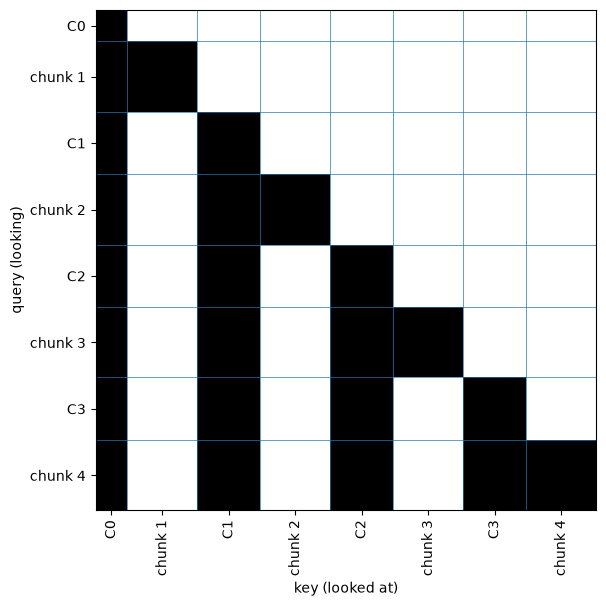

In [15]:
edges = np.cumsum([0] + [n for _, n, _, _ in layout])
mids = (edges[:-1] + edges[1:]) / 2
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.imshow(mask, cmap='Greys', interpolation='nearest')
names = [name for name, *_ in layout]
ax.set_xticks(mids, names, rotation=90)
ax.set_yticks(mids, names)
ax.set_xlabel('key (looked at)')
ax.set_ylabel('query (looking)')
for e in edges[1:-1]:
    ax.axhline(e - 0.5, color='tab:blue', lw=0.5)
    ax.axvline(e - 0.5, color='tab:blue', lw=0.5)
plt.show()

### step 5 — one noise level per chunk, shared by its frames and actions

Flow matching's line, as in uwm: `x_τ = (1 − τ)·noise + τ·clean` (τ = 0 pure noise, 1 clean). Each chunk draws its own τ_k; its 2 frames and 16 actions share it (paper eq. 2).


In [16]:
torch.manual_seed(0)
frames = b.frames[:, 1:].float().view(32, M, K, 3, 128, 128)  # now dropped: chunk frames only
clean = frozendict(
    frames=frames / 255 * 2 - 1,  # [B, 4, 2, 3, 128, 128]
    acts=(b.acts - stats['a_mean']) / stats['a_std'],  # [B, 4, 16, 8]
)
tau = torch.rand(32, M, device=dev)  # [B, 4], one per chunk
tf, ta = tau.view(32, M, 1, 1, 1, 1), tau.view(32, M, 1, 1)  # broadcast to frames, actions
noise = frozendict(frames=torch.randn_like(clean['frames']), acts=torch.randn_like(clean['acts']))
noisy = frozendict(
    frames=(1 - tf) * noise['frames'] + tf * clean['frames'],
    acts=(1 - ta) * noise['acts'] + ta * clean['acts'],
)
print(f'sample 0, tau per chunk: {tau[0].cpu().numpy().round(2)}')

sample 0, tau per chunk: [0.4  0.52 0.02 0.94]


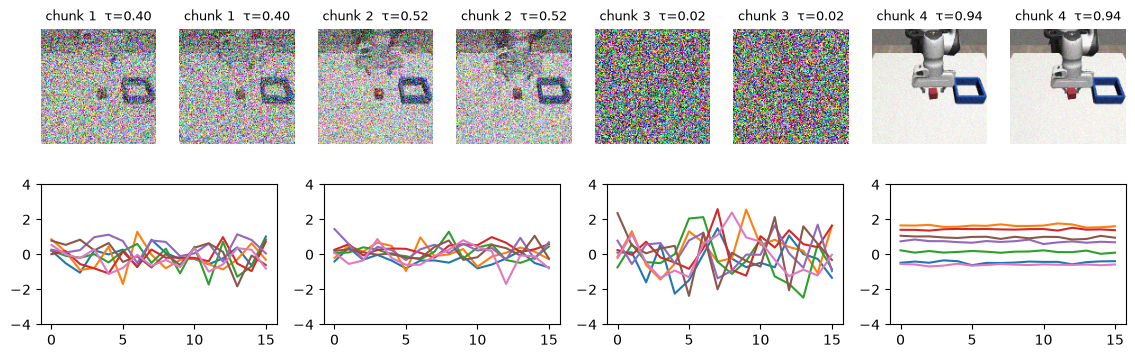

In [17]:
fig, axs = plt.subplots(2, M * K, figsize=(14, 4))
for k in range(M):
    for j in range(K):
        ax = axs[0, K * k + j]
        ax.imshow(((noisy['frames'][0, k, j].permute(1, 2, 0) + 1) / 2).clamp(0, 1).cpu())
        ax.set_title(f'chunk {k + 1}  τ={tau[0, k]:.2f}', fontsize=9)
        ax.axis('off')
    ax = fig.add_subplot(2, M, M + k + 1)
    ax.plot(noisy['acts'][0, k, :, :7].cpu())  # 7 arm joints, std units
    ax.set_ylim(-4, 4)
for ax in axs[1]:
    ax.remove()
plt.show()

### step 6 — one forward pass, loose pieces

New pieces: τ → a D-vector added to every token of its chunk (so the net knows how noisy that chunk is), a learned position per token, a small transformer run with the step-4 mask, and two output layers that read the noisy chunks back: patch velocity (768) and action velocity (8).


In [18]:
torch.manual_seed(0)
layer = nn.TransformerEncoderLayer(
    D,
    nhead=4,
    dim_feedforward=4 * D,
    dropout=0.0,
    activation='gelu',
    batch_first=True,
    norm_first=True,
)
core = nn.ModuleDict(
    dict(
        tau=nn.Linear(1, D),  # noise level -> added to its chunk's tokens
        pos=nn.Embedding(len(t), D),  # one learned position per token
        body=nn.TransformerEncoder(layer, num_layers=4, enable_nested_tensor=False),
        frame_out=nn.Linear(D, 3 * P * P),  # velocity of each patch
        action_out=nn.Linear(D, 8),  # velocity of each action
    )
).to(dev)
n_params = sum(p.numel() for m in (embed, core) for p in m.parameters())
print(f'{n_params / 1e6:.2f}M params')

1.13M params


In [19]:
# the 1028-token training sequence for batch b: C0, chunk 1, C1, chunk 2, ..., chunk 4
noisy_patches = rearrange(
    noisy['frames'], 'b m k c (h p) (w q) -> b m (k h w) (p q c)', p=P, q=P
)  # [B, 4, 128, 768]
blocks = [tok['frame'][:, 0]]  # C0: now, clean
for k in range(M):
    chunk = [
        tok['state'][:, k, None],  # joints at the chunk's start
        embed['frame'](noisy_patches[:, k]),
        embed['action'](noisy['acts'][:, k]),
    ]
    blocks.append(torch.cat(chunk, 1) + core['tau'](tau[:, k, None])[:, None])
    if k < M - 1:
        blocks.append(tok['frame'][:, 1 + K * k : 1 + K * (k + 1)].flatten(1, 2))  # C_(k+1)
x = torch.cat(blocks, 1) + core['pos'].weight  # [B, 1028, D]
print(f'{x.shape=}')

x.shape=torch.Size([32, 1028, 128])


In [20]:
starts = edges[1::2]  # where each noisy chunk begins in the sequence
idx = frozendict(
    frame=torch.tensor(np.stack([s + 1 + np.arange(K * 64) for s in starts])),  # [4, 128]
    action=torch.tensor(np.stack([s + 1 + K * 64 + np.arange(H) for s in starts])),  # [4, 16]
)
h = core['body'](x, mask=~mask.to(dev))  # torch's mask: True = blocked
v = frozendict(
    frames=core['frame_out'](h[:, idx['frame']]),  # [B, 4, 128, 768]
    acts=core['action_out'](h[:, idx['action']]),  # [B, 4, 16, 8]
)
print({k: tuple(x.shape) for k, x in v.items()})

{'frames': (32, 4, 128, 768), 'acts': (32, 4, 16, 8)}


### step 7 — the loss, and a check that the future doesn't leak

Target velocity = clean − noise (the straight line's slope, paper eq. 3); loss = MSE on frames and on actions. Then: change chunk 4's input, and nothing outside chunk 4 may change.


In [21]:
import torch.nn.functional as F

to_patch = 'b m k c (h p) (w q) -> b m (k h w) (p q c)'
target = frozendict(
    frames=rearrange(clean['frames'] - noise['frames'], to_patch, p=P, q=P),  # [B, 4, 128, 768]
    acts=clean['acts'] - noise['acts'],  # [B, 4, 16, 8]
)
loss = {k: round(F.mse_loss(v[k], target[k]).item(), 3) for k in v}
size = {k: round(target[k].square().mean().item(), 3) for k in target}  # loss if v were 0
print(f'untrained loss {loss}\ntarget mean square {size}')

untrained loss {'frames': 2.606, 'acts': 3.055}
target mean square {'frames': 1.66, 'acts': 1.912}


In [22]:
x2 = x.clone()
x2[:, edges[7] :] += torch.randn_like(x2[:, edges[7] :])  # scramble chunk 4 (the last block)
h2 = core['body'](x2, mask=~mask.to(dev))
diff = (h2 - h).abs().amax(dim=(0, 2))  # [1028], biggest change per token
before, inside = diff[: edges[7]].max().item(), diff[edges[7] :].max().item()
print(f'max change before chunk 4: {before:.1e}   inside chunk 4: {inside:.2f}')

max change before chunk 4: 0.0e+00   inside chunk 4: 5.07


### step 8 — the pieces packed: `WAM` and `batch_loss`

Same layers as steps 3–6 in one module; `batch_loss` does step 5's noising, the pass, and step 7's loss. Noising in patch space = noising pixels, then cutting (it's elementwise). Check: given step 6's weights and inputs, `WAM` must give the same outputs.


In [23]:
class WAM(nn.Module):
    # steps 3-6 packed: tokens -> masked transformer -> velocities of the noisy chunks
    def __init__(self):
        super().__init__()
        self.frame_in, self.action_in = nn.Linear(3 * P * P, D), nn.Linear(8, D)
        self.state_in, self.tau_in = nn.Linear(8, D), nn.Linear(1, D)
        self.pos = nn.Embedding(len(t), D)
        layer = nn.TransformerEncoderLayer(
            D,
            nhead=4,
            dim_feedforward=4 * D,
            dropout=0.0,
            activation='gelu',
            batch_first=True,
            norm_first=True,
        )
        self.body = nn.TransformerEncoder(layer, num_layers=4, enable_nested_tensor=False)
        self.frame_out, self.action_out = nn.Linear(D, 3 * P * P), nn.Linear(D, 8)
        self.register_buffer('blocked', ~mask)  # step 4, torch's convention: True = blocked
        self.register_buffer('at_frames', idx['frame'])  # [4, 128] noisy frame tokens
        self.register_buffer('at_acts', idx['action'])  # [4, 16] noisy action tokens

    def forward(self, seen, state, noisy_f, noisy_a, tau):
        # seen [B, 9, 64, 768] clean patches (now, then the chunks' frames); state [B, M, 8]
        # noisy_f [B, M, 128, 768], noisy_a [B, M, H, 8], tau [B, M]
        f = self.frame_in(seen)
        blocks = [f[:, 0]]  # C0
        for k in range(M):
            chunk = [
                self.state_in(state[:, k, None]),
                self.frame_in(noisy_f[:, k]),
                self.action_in(noisy_a[:, k]),
            ]
            blocks.append(torch.cat(chunk, 1) + self.tau_in(tau[:, k, None])[:, None])
            if k < M - 1:
                blocks.append(f[:, 1 + K * k : 1 + K * (k + 1)].flatten(1, 2))  # C_(k+1)
        h = self.body(torch.cat(blocks, 1) + self.pos.weight, mask=self.blocked)
        return self.frame_out(h[:, self.at_frames]), self.action_out(h[:, self.at_acts])

In [24]:
def batch_loss(net: WAM, b: Batch) -> tuple[torch.Tensor, torch.Tensor]:
    # steps 5-7 for a batch from get_batch: (frame loss, action loss)
    B = len(b.frames)
    seen = patches(b.frames)  # [B, 9, 64, 768]
    clean_f = seen[:, 1:].reshape(B, M, K * 64, 3 * P * P)
    clean_a = (b.acts - stats['a_mean']) / stats['a_std']
    state = (b.state - stats['s_mean']) / stats['s_std']
    tau = torch.rand(B, M, device=dev)
    noise_f, noise_a = torch.randn_like(clean_f), torch.randn_like(clean_a)
    tf, ta = tau.view(B, M, 1, 1), tau.view(B, M, 1, 1)
    v_f, v_a = net(
        seen, state, (1 - tf) * noise_f + tf * clean_f, (1 - ta) * noise_a + ta * clean_a, tau
    )
    return F.mse_loss(v_f, clean_f - noise_f), F.mse_loss(v_a, clean_a - noise_a)

In [25]:
net = WAM().to(dev)
loose = dict(
    frame_in=embed['frame'],
    action_in=embed['action'],
    state_in=embed['state'],
    tau_in=core['tau'],
    pos=core['pos'],
    body=core['body'],
    frame_out=core['frame_out'],
    action_out=core['action_out'],
)
for name, m in loose.items():
    getattr(net, name).load_state_dict(m.state_dict())  # step 6's weights
state_n = (b.state - stats['s_mean']) / stats['s_std']
out = net(patches(b.frames), state_n, noisy_patches, noisy['acts'], tau)
diff = [(out[0] - v['frames']).abs().max().item(), (out[1] - v['acts']).abs().max().item()]
print(f'max diff vs step 6 (frames, acts): {diff}')
print(f'batch_loss (fresh noise): {[round(x.item(), 3) for x in batch_loss(net, b)]}')

max diff vs step 6 (frames, acts): [1.9073486328125e-06, 7.152557373046875e-07]
batch_loss (fresh noise): [2.604, 3.009]


### step 9 — first training run: joint, on the 10 labelled demos only

The dumb whole game, no video pretraining yet. Batch 16, bf16, AdamW lr 3e-4, grad clip 1, 5k steps. Val = 32 fixed samples from the 10 held-out demos, every 500 steps.


In [26]:
@cache
def train(steps: int = 5000, B: int = 16, lr: float = 3e-4, seed: int = 0):
    # prints (frame, action) losses; out: weights (CPU),
    # log rows [step, train frame, train act, val frame, val act]
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    net = WAM().to(dev)
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    log = []
    with torch.enable_grad():
        for step in range(steps + 1):
            with torch.autocast('cuda', dtype=torch.bfloat16):
                lf, la = batch_loss(net, get_batch(eps['labelled'], B, rng))
            opt.zero_grad()
            (lf + la).backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
            if step % 500 == 0:
                with torch.no_grad(), torch.autocast('cuda', dtype=torch.bfloat16):
                    val_b = get_batch(eps['val'], 32, np.random.default_rng(1))
                    vf, va = batch_loss(net, val_b)
                log.append([step, lf.item(), la.item(), vf.item(), va.item()])
                print(f'{step:5d}  train {lf:.3f} {la:.3f}   val {vf:.3f} {va:.3f}')
    return frozendict(weights={k: v.cpu() for k, v in net.state_dict().items()}, log=np.array(log))

train: cached, 2 call(s) stored


In [27]:
run = train()

    0  train 2.558 2.470   val 2.461 2.673
  500  train 1.083 0.205   val 1.086 0.316
 1000  train 1.044 0.134   val 1.050 0.194
 1500  train 1.036 0.098   val 1.035 0.205
 2000  train 1.026 0.094   val 1.025 0.192
 2500  train 1.012 0.081   val 1.015 0.185
 3000  train 1.006 0.082   val 1.005 0.148
 3500  train 0.995 0.065   val 0.999 0.152
 4000  train 0.993 0.085   val 0.991 0.134
 4500  train 0.981 0.046   val 0.985 0.153
 5000  train 0.979 0.094   val 0.981 0.160


### step 10 — the dreams: chunk 1 denoised from pure noise

Given only the real now-frame and joints, start chunk 1 at τ = 0 and take 10 Euler steps to τ = 1 (flow_matching.ipynb). Chunks 2–4 can't reach chunk 1 (step 4's mask), so they stay noise; the clean future frames are zeroed to be sure.


In [28]:
@torch.no_grad()
def dream(net: WAM, frames: Tensor, state: Tensor, steps: int = 10):
    # chunk 1 from noise, given frames [B, 9, 3, 128, 128] uint8 (only [:, 0] read), raw joints
    # state [B, M, 8]; out: frame patches [B, 128, 768] in [-1, 1], actions [B, 16, 8] std units
    B = len(frames)
    seen = patches(frames)
    seen[:, 1:] = 0  # only now is known
    state = (state - stats['s_mean']) / stats['s_std']
    x_f = torch.randn(B, M, K * 64, 3 * P * P, device=dev)
    x_a = torch.randn(B, M, H, 8, device=dev)
    tau = torch.zeros(B, M, device=dev)
    for i in range(steps):
        tau[:, 0] = i / steps
        v_f, v_a = net(seen, state, x_f, x_a, tau)
        x_f[:, 0] += v_f[:, 0] / steps
        x_a[:, 0] += v_a[:, 0] / steps
    return x_f[:, 0], x_a[:, 0]

In [29]:
net = WAM().to(dev)
net.load_state_dict(run['weights'])
torch.manual_seed(0)
val_b = get_batch(eps['val'], 32, np.random.default_rng(2))
d_f, d_a = dream(net, val_b.frames, val_b.state)
real = patches(val_b.frames)
real_f = real[:, 1 : 1 + K].flatten(1, 2)  # [B, 128, 768] chunk 1's 2 frames
real_a = (val_b.acts[:, 0] - stats['a_mean']) / stats['a_std']
mse = lambda x, y: ((x - y) / 2).square().mean().item()  # pixels in [0, 1] units
copy_now = mse(real[:, 0].repeat(1, K, 1), real_f)
print(f'frames: dream {mse(d_f, real_f):.4f}   copy now {copy_now:.4f}')
print(f'actions (std units): dream {(d_a - real_a).square().mean():.3f}')

frames: dream 0.2462   copy now 0.0148
actions (std units): dream 0.045


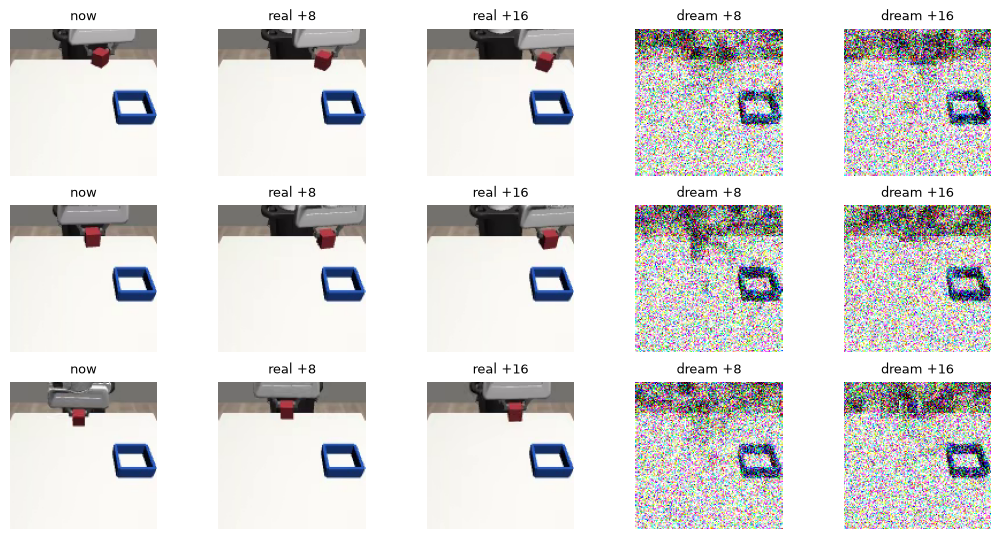

In [30]:
to_img = lambda x: (
    rearrange((x + 1) / 2, '(k h w) (p q c) -> k h p w q c', k=K, h=8, p=P, q=P)
    .flatten(1, 2)
    .flatten(2, 3)
    .clamp(0, 1)
    .cpu()
)  # [128, 768] -> [K, 128, 128, 3]
fig, axs = plt.subplots(3, 1 + 2 * K, figsize=(13, 6.5))
for r in range(3):
    ims = [to_img(real[r, 0].repeat(K, 1))[0], *to_img(real_f[r]), *to_img(d_f[r])]
    names = ['now', 'real +8', 'real +16', 'dream +8', 'dream +16']
    for ax, im, name in zip(axs[r], ims, names):
        ax.imshow(im)
        ax.set_title(name, fontsize=9)
        ax.axis('off')
plt.show()

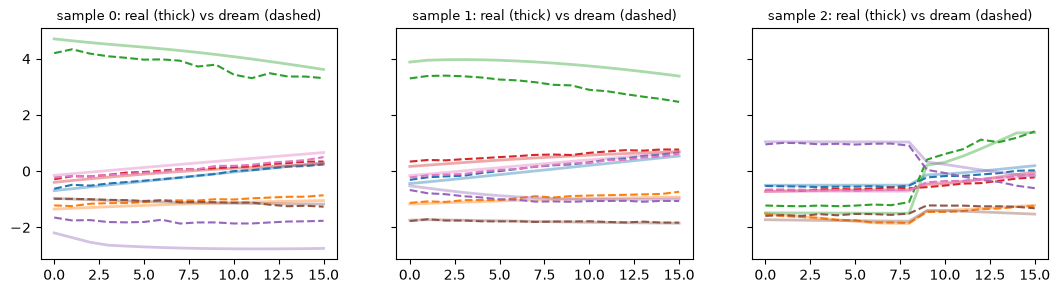

In [31]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3), sharey=True)
for r, ax in enumerate(axs):
    for j in range(7):
        line = ax.plot(real_a[r, :, j].cpu(), lw=2, alpha=0.4)[0]
        ax.plot(d_a[r, :, j].cpu(), '--', color=line.get_color())
    ax.set_title(f'sample {r}: real (thick) vs dream (dashed)', fontsize=9)
plt.show()

### step 11 — rollout in T1: the dumb whole game's number

Policy: dream chunk 1 from the current frame and joints (step 10), play its first `n_exec` actions, dream again. Same 20 env seeds (1000–1019) and n_exec 8 / 16 as uwm2 (10 labelled: 16 + 14 = 30/40).


In [32]:
from collections import Counter

from uwm_parts import make_sim

env = make_sim()


def act(net: WAM, obs) -> np.ndarray:
    # current top frame + joints -> [16, 8] actions, chunk 1 dreamed
    frame = torch.from_numpy(obs.images['top']).permute(2, 0, 1).to(dev)  # [3, 128, 128] uint8
    frames = frame.expand(1, 1 + M * K, -1, -1, -1)  # only [:, 0] is read
    state = torch.from_numpy(obs.state).to(dev).expand(1, M, -1)
    pixels = net.frame_in.in_features == 3 * P * P  # else latents (WAMz, step 22)
    _, d_a = (dream if pixels else dream_z)(net, frames, state)
    chunk = (d_a * stats['a_std'] + stats['a_mean'])[0].cpu().numpy()
    chunk[:, 7] = np.clip(chunk[:, 7], 0.0, 1.0)  # gripper commands stay in [0, 1]
    return chunk


def rollout(net: WAM, seed: int, n_exec: int, seen: list | None = None) -> tuple[bool, str, int]:
    # seen: if given, every top frame is appended to it
    obs, plan = env.reset(seed=seed), []
    for step in range(600):
        if seen is not None:
            seen.append(obs.images['top'])
        if not plan:
            plan = list(act(net, obs)[:n_exec])
        r = env.step(plan.pop(0))
        obs = r.observation
        if r.terminated or r.truncated:
            break
    return r.success, str(r.failure_mode), step + 1

In [33]:
@cache
def sweep(n_exec: int) -> dict[int, tuple]:
    # step 9's weights over env seeds 1000-1019; out: {seed: (ok, mode, steps)}
    torch.manual_seed(n_exec)  # the sampling noise, fixed per call
    res = {seed: rollout(net, seed, n_exec) for seed in range(1000, 1020)}
    fails = Counter(mode for ok, mode, _ in res.values() if not ok)
    print(
        f'n_exec {n_exec:2d}: {sum(ok for ok, _, _ in res.values()):2d}/20   failures {dict(fails)}'
    )
    return res

sweep: cached, 2 call(s) stored


In [34]:
sweeps = {n_exec: sweep(n_exec) for n_exec in [8, 16]}
print('uwm2, UWMxx on the same 10 labelled demos: 16, 14')

n_exec  8:  2/20   failures {'wrong_target': 6, 'dropped': 1, 'no_grasp': 11}
n_exec 16:  2/20   failures {'no_grasp': 11, 'wrong_target': 7}
uwm2, UWMxx on the same 10 labelled demos: 16, 14


### step 12 — control: the same run, actions only

`train` with the frame loss switched off (still printed). If the sim score jumps toward uwm2's 30/40, the broken frame half was dragging the actions down.


In [35]:
@cache
def train_acts(steps: int = 5000, B: int = 16, lr: float = 3e-4, seed: int = 0):
    # train with the frame loss switched off; prints (frame, action) losses; out: weights (CPU),
    # log rows [step, train frame, train act, val frame, val act]
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    net = WAM().to(dev)
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    log = []
    with torch.enable_grad():
        for step in range(steps + 1):
            with torch.autocast('cuda', dtype=torch.bfloat16):
                lf, la = batch_loss(net, get_batch(eps['labelled'], B, rng))
            opt.zero_grad()
            la.backward()  # frame loss logged, not trained
            torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
            if step % 500 == 0:
                with torch.no_grad(), torch.autocast('cuda', dtype=torch.bfloat16):
                    val_b = get_batch(eps['val'], 32, np.random.default_rng(1))
                    vf, va = batch_loss(net, val_b)
                log.append([step, lf.item(), la.item(), vf.item(), va.item()])
                print(f'{step:5d}  train {lf:.3f} {la:.3f}   val {vf:.3f} {va:.3f}')
    return frozendict(weights={k: v.cpu() for k, v in net.state_dict().items()}, log=np.array(log))

train_acts: cached, 1 call(s) stored


In [36]:
run_acts = train_acts()

    0  train 2.558 2.470   val 2.637 2.736
  500  train 3.338 0.226   val 3.366 0.352
 1000  train 3.460 0.143   val 3.468 0.209
 1500  train 3.538 0.107   val 3.647 0.230
 2000  train 3.732 0.097   val 3.766 0.226
 2500  train 3.808 0.081   val 3.776 0.200
 3000  train 3.872 0.079   val 3.808 0.172
 3500  train 3.883 0.066   val 3.925 0.166
 4000  train 3.983 0.085   val 3.969 0.145
 4500  train 3.931 0.037   val 4.042 0.179
 5000  train 4.123 0.092   val 4.102 0.174


In [37]:
runs = {'joint': run, 'acts': run_acts}


@cache
def sweep_run(name: str, n_exec: int) -> dict[int, tuple]:
    # step 11's sweep with runs[name]'s weights; out: {seed: (ok, mode, steps)}
    net = WAM().to(dev)
    net.load_state_dict(runs[name]['weights'])
    torch.manual_seed(n_exec)  # the sampling noise, fixed per call
    res = {seed: rollout(net, seed, n_exec) for seed in range(1000, 1020)}
    fails = Counter(mode for ok, mode, _ in res.values() if not ok)
    print(
        f'n_exec {n_exec:2d}: {sum(ok for ok, _, _ in res.values()):2d}/20   failures {dict(fails)}'
    )
    return res

sweep_run: cached, 6 call(s) stored


In [38]:
sweeps_acts = {n_exec: sweep_run('acts', n_exec) for n_exec in [8, 16]}
print('joint (step 11): 2, 2   uwm2 UWMxx: 16, 14')

n_exec  8:  0/20   failures {'no_grasp': 20}
n_exec 16:  0/20   failures {'no_grasp': 20}
joint (step 11): 2, 2   uwm2 UWMxx: 16, 14


### step 13 — watch one rollout: where does it go wrong?

Joint model (step 9), env seed 1000, n_exec 8. A frame every 25 steps, and the video.


(False, 'wrong_target', 600)


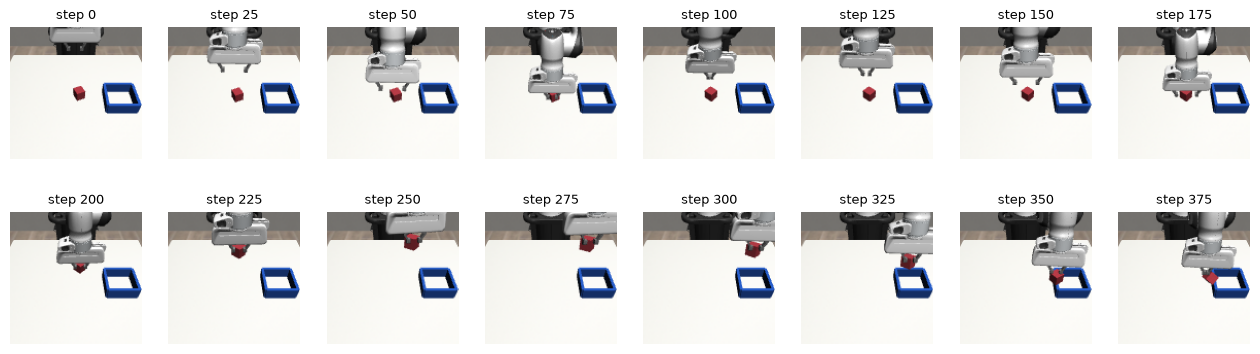

In [39]:
torch.manual_seed(8)
seen = []
print(rollout(net, 1000, 8, seen))  # net = step 9's weights (loaded in step 10)
fig, axs = plt.subplots(2, 8, figsize=(16, 4.4))
for ax, i in zip(axs.flat, range(0, len(seen), 25)):
    ax.imshow(seen[i])
    ax.set_title(f'step {i}', fontsize=9)
    ax.axis('off')
plt.show()

In [40]:
import imageio
from IPython.display import Video

imageio.mimsave('../scratch/dreamzero_seed1000.mp4', seen, fps=20)
Video('../scratch/dreamzero_seed1000.mp4', embed=True, width=320)

### step 14 — the rollout knew the task, just imprecise: train as long as uwm2

Seed 1000 (step 13): reached, missed the first grasp, grasped on the second try, carried, set it on the bin's rim. uwm2 saw 10k × 64 = 640k samples; step 9 saw 80k. Same 640k here as 20k × 32 (64 may not fit in 8 GB).


In [41]:
run_long = train(steps=20000, B=32)
runs['long'] = run_long

    0  train 2.553 2.445   val 2.443 2.576
  500  train 1.085 0.213   val 1.086 0.317
 1000  train 1.047 0.123   val 1.045 0.191
 1500  train 1.035 0.099   val 1.033 0.183
 2000  train 1.022 0.095   val 1.024 0.162
 2500  train 1.014 0.061   val 1.015 0.182
 3000  train 1.008 0.103   val 1.006 0.174
 3500  train 0.995 0.041   val 0.998 0.170
 4000  train 0.988 0.070   val 0.991 0.131
 4500  train 0.982 0.040   val 0.983 0.120
 5000  train 0.975 0.047   val 0.975 0.157
 5500  train 0.969 0.038   val 0.968 0.155
 6000  train 0.963 0.050   val 0.967 0.163
 6500  train 0.961 0.049   val 0.959 0.147
 7000  train 0.957 0.085   val 0.956 0.166
 7500  train 0.948 0.033   val 0.957 0.206
 8000  train 0.945 0.035   val 0.946 0.175
 8500  train 0.944 0.055   val 0.943 0.143
 9000  train 0.942 0.039   val 0.941 0.161
 9500  train 0.939 0.046   val 0.940 0.182
10000  train 0.932 0.040   val 0.936 0.161
10500  train 0.926 0.038   val 0.937 0.205
11000  train 0.928 0.035   val 0.927 0.171
11500  trai

In [42]:
sweeps_long = {n_exec: sweep_run('long', n_exec) for n_exec in [8, 16]}
print('joint 5k (step 11): 2, 2   uwm2 UWMxx: 16, 14')

n_exec  8:  1/20   failures {'wrong_target': 14, 'dropped': 5}
n_exec 16:  9/20   failures {'wrong_target': 7, 'no_grasp': 3, 'dropped': 1}
joint 5k (step 11): 2, 2   uwm2 UWMxx: 16, 14


### step 15 — coverage: `now` anywhere in a demo

The 20k model grasps but releases outside the bin (wrong_target 21 of 30 failures). `get_batch` drew `now` only up to 64 steps before a demo's end, and the sim uses chunk 1 alone, so chunk 1 never trained from a carry/place/release frame. `to_end=True`: any step; rows past the end repeat the last frame and action (the robot holds still). Val batch unchanged, so losses compare.


In [43]:
@cache
def train_full(steps: int = 5000, B: int = 16, lr: float = 3e-4, seed: int = 0):
    # `now` anywhere in a demo (to_end); prints (frame, action) losses; out: weights (CPU),
    # log rows [step, train frame, train act, val frame, val act]
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    net = WAM().to(dev)
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    log = []
    with torch.enable_grad():
        for step in range(steps + 1):
            with torch.autocast('cuda', dtype=torch.bfloat16):
                lf, la = batch_loss(net, get_batch(eps['labelled'], B, rng, to_end=True))
            opt.zero_grad()
            (lf + la).backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
            if step % 500 == 0:
                with torch.no_grad(), torch.autocast('cuda', dtype=torch.bfloat16):
                    val_b = get_batch(eps['val'], 32, np.random.default_rng(1))
                    vf, va = batch_loss(net, val_b)
                log.append([step, lf.item(), la.item(), vf.item(), va.item()])
                print(f'{step:5d}  train {lf:.3f} {la:.3f}   val {vf:.3f} {va:.3f}')
    return frozendict(weights={k: v.cpu() for k, v in net.state_dict().items()}, log=np.array(log))

train_full: cached, 1 call(s) stored


In [44]:
run_full = train_full(steps=20000, B=32)
runs['full'] = run_full

    0  train 2.557 2.708   val 2.426 2.677
  500  train 1.094 0.245   val 1.094 0.342
 1000  train 1.050 0.133   val 1.049 0.197
 1500  train 1.037 0.101   val 1.037 0.183
 2000  train 1.024 0.096   val 1.028 0.156
 2500  train 1.016 0.068   val 1.020 0.170
 3000  train 1.011 0.101   val 1.011 0.147
 3500  train 0.998 0.044   val 1.003 0.152
 4000  train 0.992 0.066   val 0.996 0.118
 4500  train 0.985 0.042   val 0.989 0.108
 5000  train 0.981 0.054   val 0.981 0.140
 5500  train 0.974 0.037   val 0.975 0.136
 6000  train 0.967 0.043   val 0.973 0.142
 6500  train 0.964 0.044   val 0.965 0.142
 7000  train 0.961 0.081   val 0.962 0.124
 7500  train 0.952 0.035   val 0.963 0.179
 8000  train 0.948 0.036   val 0.952 0.127
 8500  train 0.947 0.054   val 0.949 0.131
 9000  train 0.945 0.034   val 0.946 0.143
 9500  train 0.942 0.049   val 0.945 0.166
10000  train 0.935 0.042   val 0.941 0.151
10500  train 0.929 0.039   val 0.942 0.178
11000  train 0.930 0.039   val 0.932 0.143
11500  trai

In [45]:
sweeps_full = {n_exec: sweep_run('full', n_exec) for n_exec in [8, 16]}
print('20k, now up to 64 before the end (step 14): 1, 9')

n_exec  8: 11/20   failures {'wrong_target': 1, 'no_grasp': 7, 'dropped': 1}
n_exec 16: 13/20   failures {'no_grasp': 6, 'dropped': 1}
20k, now up to 64 before the end (step 14): 1, 9


### step 16 — the video compressor (VAE), loose pieces

Raw patches failed because a 768-number patch can't pass through a 128-dim token (step 10). DreamZero's backbone (Wan) never sees pixels: a VAE squeezes each frame into a small latent grid and the transformer denoises that. Ours: 128 × 128 × 3 → 16 × 16 × 4 (8× down per side, 48× fewer numbers), one frame at a time (Wan also squeezes 4 frames into 1; later). The encoder gives a mean and a log-variance per latent; a sample is mean + noise × std.


In [46]:
def down(i: int, o: int) -> nn.Sequential:
    # halves height and width
    return nn.Sequential(nn.Conv2d(i, o, 4, stride=2, padding=1), nn.GroupNorm(8, o), nn.SiLU())


def up(i: int, o: int) -> nn.Sequential:
    # doubles height and width
    return nn.Sequential(
        nn.Upsample(scale_factor=2), nn.Conv2d(i, o, 3, padding=1), nn.GroupNorm(8, o), nn.SiLU()
    )


Z = 4  # latent channels
torch.manual_seed(0)
vae = nn.ModuleDict(
    dict(
        enc=nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            down(32, 64),
            down(64, 128),
            down(128, 128),
            nn.Conv2d(128, 2 * Z, 1),  # mean and log-variance
        ),
        dec=nn.Sequential(
            nn.Conv2d(Z, 128, 3, padding=1),
            up(128, 128),
            up(128, 64),
            up(64, 32),
            nn.Conv2d(32, 3, 3, padding=1),
        ),
    )
).to(dev)
print(f'{sum(p.numel() for p in vae.parameters()) / 1e6:.2f}M params')

0.67M params


In [47]:
x = b.frames[:, 0].float() / 255 * 2 - 1  # [32, 3, 128, 128] in [-1, 1]
mean, logvar = vae['enc'](x).chunk(2, dim=1)  # [32, 4, 16, 16] each
z = mean + torch.randn_like(mean) * (0.5 * logvar).exp()
recon = vae['dec'](z)
print(f'{x.shape=}\n{mean.shape=}\n{recon.shape=}')
print(f'numbers per frame: {x[0].numel()} -> {z[0].numel()}')

x.shape=torch.Size([32, 3, 128, 128])
mean.shape=torch.Size([32, 4, 16, 16])
recon.shape=torch.Size([32, 3, 128, 128])
numbers per frame: 49152 -> 1024


### step 17 — the VAE's loss: rebuild the frame, keep latents near N(0, 1)

Reconstruction: MSE between frame and decoded frame. KL: how far each latent's N(mean, std²) is from N(0, 1), per number. Small weight β: we want sharp frames first; the KL only keeps latents on the noise's scale so the transformer can denoise them.


In [48]:
"""
KL( N(μ, σ²) ‖ N(0, 1) ) per number, with v = log σ²:

    KL = ∫ q log(q / p)
       = E_q[ −log σ − (x − μ)²/(2σ²) + x²/2 ]
       = −log σ − 1/2 + (σ² + μ²)/2            (E_q (x−μ)² = σ², E_q x² = σ² + μ²)
       = ½ (μ² + e^v − 1 − v)

0 exactly when μ = 0 and v = 0 (σ = 1); grows with |μ| and with σ away from 1.
"""


def vae_loss(vae: nn.ModuleDict, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    # x [B, 3, 128, 128] in [-1, 1]; out: (reconstruction MSE, KL per latent number)
    mean, logvar = vae['enc'](x).chunk(2, dim=1)
    z = mean + torch.randn_like(mean) * (0.5 * logvar).exp()
    recon = F.mse_loss(vae['dec'](z), x)
    kl = 0.5 * (mean.square() + logvar.exp() - 1 - logvar).mean()
    return recon, kl

In [49]:
torch.manual_seed(0)
recon_l, kl_l = vae_loss(vae, x)
print(f'untrained: recon {recon_l:.3f}   KL {kl_l:.4f}   latent mean std {mean.std():.3f}')
print(f'recon of a flat grey guess (predict 0): {x.square().mean():.3f}')

untrained: recon 0.642   KL 0.0918   latent mean std 0.332
recon of a flat grey guess (predict 0): 0.651


### step 18 — train the VAE on every train frame (labelled and video-only alike)

No actions needed, so all 90 train demos count: the first piece that uses the video-only demos. Batch 64 frames, AdamW lr 1e-3, β = 1e-3, 5k steps. Val = every 40th frame of the 10 held-out demos.


In [50]:
import copy


@cache
def train_vae(steps: int = 5000, B: int = 64, lr: float = 1e-3, beta: float = 1e-3, seed: int = 0):
    # prints (recon, KL); out: weights (CPU), log rows [step, train recon, KL, val recon, KL]
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    net = copy.deepcopy(vae)  # step 16's untrained pieces
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    rows = np.flatnonzero(~np.isin(episode, eps['val']))  # every train frame
    val_rows = np.flatnonzero(np.isin(episode, eps['val']))[::40]
    val_x = gpu['top'][val_rows].float() / 255 * 2 - 1
    log = []
    with torch.enable_grad():
        for step in range(steps + 1):
            x = gpu['top'][rng.choice(rows, B)].float() / 255 * 2 - 1
            with torch.autocast('cuda', dtype=torch.bfloat16):
                rec, kl = vae_loss(net, x)
            opt.zero_grad()
            (rec + beta * kl).backward()
            opt.step()
            if step % 500 == 0:
                with torch.no_grad(), torch.autocast('cuda', dtype=torch.bfloat16):
                    v_rec, v_kl = vae_loss(net, val_x)
                log.append([step, rec.item(), kl.item(), v_rec.item(), v_kl.item()])
                print(f'{step:5d}  train {rec:.4f} {kl:.3f}   val {v_rec:.4f} {v_kl:.3f}')
    return frozendict(weights={k: v.cpu() for k, v in net.state_dict().items()}, log=np.array(log))

train_vae: cached, 1 call(s) stored


In [51]:
run_vae = train_vae()

    0  train 0.6472 0.091   val 0.3543 0.621
  500  train 0.0079 1.466   val 0.0080 1.469
 1000  train 0.0058 1.389   val 0.0052 1.396
 1500  train 0.0036 1.276   val 0.0039 1.300
 2000  train 0.0034 1.220   val 0.0035 1.195
 2500  train 0.0037 1.281   val 0.0035 1.260
 3000  train 0.0030 1.171   val 0.0029 1.154
 3500  train 0.0027 1.131   val 0.0026 1.143
 4000  train 0.0025 1.108   val 0.0025 1.095
 4500  train 0.0024 1.050   val 0.0023 1.062
 5000  train 0.0021 1.069   val 0.0022 1.068


### step 19 — how good are the rebuilt frames, and what scale are the latents?

Rebuild from the mean (no sampling) on held-out frames. Pixel error in [0, 1] units, as step 10 (copy-now 0.0148, step 10's dreams 0.246). Latent scale: the transformer adds N(0, 1) noise, so the latents should be about unit-sized.


In [52]:
vae_t = copy.deepcopy(vae)
vae_t.load_state_dict(run_vae['weights'])
val_x = gpu['top'][np.flatnonzero(np.isin(episode, eps['val']))[::40]].float() / 255 * 2 - 1
mean, logvar = vae_t['enc'](val_x).chunk(2, dim=1)  # [n, 4, 16, 16]
rebuilt = vae_t['dec'](mean)
err = ((rebuilt - val_x) / 2).square().mean()
print(f'{len(val_x)} held-out frames   pixel MSE, [0, 1] units: {err:.5f}')
print(f'latent mean: std per channel {mean.std(dim=(0, 2, 3)).cpu().numpy().round(2)}')
print(f'latent sigma (sampling noise): average {(0.5 * logvar).exp().mean():.3f}')

54 held-out frames   pixel MSE, [0, 1] units: 0.00050
latent mean: std per channel [0.85 0.78 0.79 0.98]
latent sigma (sampling noise): average 0.452


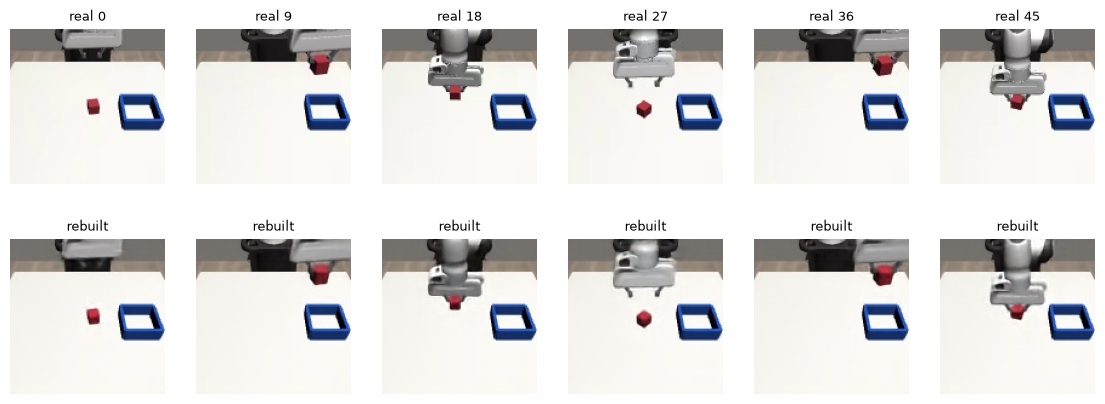

In [53]:
fig, axs = plt.subplots(2, 6, figsize=(14, 5))
for i, r in enumerate(range(0, len(val_x), len(val_x) // 6)[:6]):
    for row, im in enumerate([val_x[r], rebuilt[r]]):
        axs[row, i].imshow(((im.permute(1, 2, 0) + 1) / 2).clamp(0, 1).cpu())
        axs[row, i].axis('off')
    axs[0, i].set_title(f'real {r}', fontsize=9)
    axs[1, i].set_title('rebuilt', fontsize=9)
plt.show()

### step 20 — every frame as a latent, once

The transformer will read and denoise latents, never pixels. Encode all 21k frames with step 18's VAE (the mean, no sampling), keep them on the GPU (~85 MB).


In [54]:
@cache
def encode_all() -> torch.Tensor:
    # out: [N, 4, 16, 16] float32 on the CPU, the latent mean of every frame
    out = [
        vae_t['enc'](gpu['top'][i : i + 512].float() / 255 * 2 - 1).chunk(2, dim=1)[0].cpu()
        for i in range(0, len(top), 512)
    ]
    return torch.cat(out)

encode_all: cached, 1 call(s) stored


In [55]:
lat = encode_all().to(dev)  # [N, 4, 16, 16]
print(
    f'{lat.shape=}   {lat.numel() * 4 / 2**20:.0f} MB   std {lat.std():.3f}   mean {lat.mean():.3f}'
)

lat.shape=torch.Size([21295, 4, 16, 16])   83 MB   std 0.853   mean -0.010


### step 21 — latents as tokens

`Batch` now carries its frames' rows, so `lat[b.rows]` is a sample's latents. Each 16 × 16 × 4 latent is cut into 2 × 2 squares: 64 tokens of 16 numbers (pixel patches were 64 of 768). Check: cut, reassemble, decode with the VAE.


In [56]:
def latent_tokens(z: torch.Tensor) -> torch.Tensor:
    # [..., 4, 16, 16] -> [..., 64, 16], one row per 2 x 2 square
    return rearrange(z, '... c (h p) (w q) -> ... (h w) (p q c)', p=2, q=2)


def latent_from_tokens(t: torch.Tensor) -> torch.Tensor:
    # [..., 64, 16] -> [..., 4, 16, 16], the inverse
    return rearrange(t, '... (h w) (p q c) -> ... c (h p) (w q)', h=8, p=2, q=2)

zt.shape=torch.Size([32, 9, 64, 16])   round trip exact: True


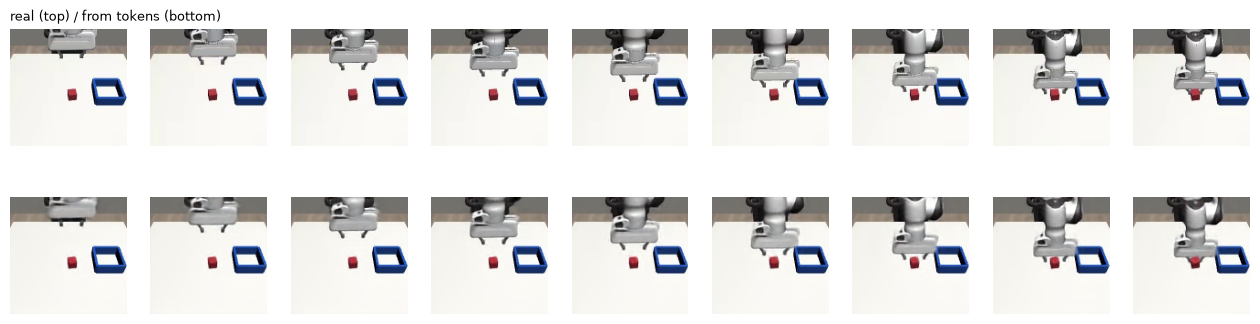

In [57]:
b = get_batch(eps['labelled'], 32, np.random.default_rng(0))  # step 2's batch, now with rows
zt = latent_tokens(lat[b.rows])  # [32, 9, 64, 16]
print(f'{zt.shape=}   round trip exact: {torch.equal(latent_from_tokens(zt), lat[b.rows])}')
fig, axs = plt.subplots(2, 9, figsize=(16, 4))
for i, im in enumerate(vae_t['dec'](latent_from_tokens(zt[0]))):  # sample 0's 9 frames
    axs[0, i].imshow(np.transpose(b.frames[0, i].cpu().numpy(), (1, 2, 0)))
    axs[1, i].imshow(((im.permute(1, 2, 0) + 1) / 2).clamp(0, 1).cpu())
    axs[0, i].axis('off')
    axs[1, i].axis('off')
axs[0, 0].set_title('real (top) / from tokens (bottom)', fontsize=9, loc='left')
plt.show()

### step 22 — `WAM` on latents

Same model, same sequence layout; only the frame layers change size, 768 → 16 numbers per token. `batch_loss_z` = `batch_loss` with latent tokens in place of pixel patches.


In [58]:
class WAMz(WAM):
    # WAM reading and denoising latent tokens [.., 64, 16] instead of pixel patches
    def __init__(self):
        super().__init__()
        self.frame_in, self.frame_out = nn.Linear(4 * 2 * 2, D), nn.Linear(D, 4 * 2 * 2)


def batch_loss_z(net: WAMz, b: Batch) -> tuple[torch.Tensor, torch.Tensor]:
    # batch_loss on latents: (frame loss, action loss)
    B = len(b.rows)
    seen = latent_tokens(lat[b.rows])  # [B, 9, 64, 16]
    clean_f = seen[:, 1:].reshape(B, M, K * 64, 16)
    clean_a = (b.acts - stats['a_mean']) / stats['a_std']
    state = (b.state - stats['s_mean']) / stats['s_std']
    tau = torch.rand(B, M, device=dev)
    noise_f, noise_a = torch.randn_like(clean_f), torch.randn_like(clean_a)
    tf, ta = tau.view(B, M, 1, 1), tau.view(B, M, 1, 1)
    noisy_f, noisy_a = (1 - tf) * noise_f + tf * clean_f, (1 - ta) * noise_a + ta * clean_a
    v_f, v_a = net(seen, state, noisy_f, noisy_a, tau)
    return F.mse_loss(v_f, clean_f - noise_f), F.mse_loss(v_a, clean_a - noise_a)

In [59]:
torch.manual_seed(0)
netz = WAMz().to(dev)
print(f'WAMz {sum(p.numel() for p in netz.parameters()) / 1e6:.2f}M params   (WAM 1.13M)')
print(f'untrained loss (frame, action): {[round(x.item(), 3) for x in batch_loss_z(netz, b)]}')
print(f'predicting 0 would score: frame {lat.var().item() + 1:.2f}, action ~1.9 (step 7)')

WAMz 0.93M params   (WAM 1.13M)
untrained loss (frame, action): [2.518, 2.534]
predicting 0 would score: frame 1.73, action ~1.9 (step 7)


### step 23 — train `WAMz`: step 15's recipe on latents

20k steps, batch 32, `now` anywhere in a demo, 10 labelled demos. Watch the frame loss: pixels stalled near 0.9 (the noise's own size); latents should go well below.


In [60]:
@cache
def train_z(steps: int = 5000, B: int = 16, lr: float = 3e-4, seed: int = 0):
    # train_full on latents (WAMz); prints (frame, action) losses; out: weights (CPU),
    # log rows [step, train frame, train act, val frame, val act]
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    net = WAMz().to(dev)
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    log = []
    with torch.enable_grad():
        for step in range(steps + 1):
            with torch.autocast('cuda', dtype=torch.bfloat16):
                lf, la = batch_loss_z(net, get_batch(eps['labelled'], B, rng, to_end=True))
            opt.zero_grad()
            (lf + la).backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
            if step % 500 == 0:
                with torch.no_grad(), torch.autocast('cuda', dtype=torch.bfloat16):
                    val_b = get_batch(eps['val'], 32, np.random.default_rng(1))
                    vf, va = batch_loss_z(net, val_b)
                log.append([step, lf.item(), la.item(), vf.item(), va.item()])
                print(f'{step:5d}  train {lf:.3f} {la:.3f}   val {vf:.3f} {va:.3f}')
    return frozendict(weights={k: v.cpu() for k, v in net.state_dict().items()}, log=np.array(log))

train_z: cached, 1 call(s) stored


In [61]:
run_z = train_z(steps=20000, B=32)

    0  train 2.526 2.748   val 2.290 2.622
  500  train 0.867 0.328   val 0.926 0.403
 1000  train 0.608 0.192   val 0.633 0.243
 1500  train 0.526 0.123   val 0.537 0.235
 2000  train 0.400 0.089   val 0.496 0.204
 2500  train 0.411 0.129   val 0.470 0.198
 3000  train 0.401 0.092   val 0.446 0.176
 3500  train 0.387 0.084   val 0.417 0.155
 4000  train 0.306 0.054   val 0.416 0.179
 4500  train 0.352 0.079   val 0.412 0.175
 5000  train 0.372 0.084   val 0.415 0.223
 5500  train 0.330 0.088   val 0.399 0.193
 6000  train 0.253 0.040   val 0.369 0.163
 6500  train 0.288 0.077   val 0.361 0.167
 7000  train 0.285 0.061   val 0.352 0.136
 7500  train 0.261 0.036   val 0.361 0.163
 8000  train 0.253 0.043   val 0.351 0.169
 8500  train 0.259 0.045   val 0.353 0.170
 9000  train 0.229 0.040   val 0.335 0.161
 9500  train 0.267 0.079   val 0.339 0.180
10000  train 0.207 0.039   val 0.335 0.157
10500  train 0.216 0.045   val 0.334 0.150
11000  train 0.217 0.058   val 0.335 0.171
11500  trai

### step 24 — dreams on latents, decoded by the VAE; then the sim

`dream_z` = step 10's sampler on latent tokens: the now-frame goes in through the VAE encoder, chunk 1's 2 frames come out as latents, the VAE decoder turns them into pictures. Same held-out batch as step 10 (dream 0.246, copy-now 0.0148).


In [62]:
@torch.no_grad()
def dream_z(net: WAMz, frames: Tensor, state: Tensor, steps: int = 10):
    # dream on latents; frames [B, 9, 3, 128, 128] uint8 (only [:, 0] read), raw joints state
    # [B, M, 8]; out: latent tokens [B, 128, 16], actions [B, 16, 8] std units
    B = len(frames)
    now = vae_t['enc'](frames[:, 0].float() / 255 * 2 - 1).chunk(2, dim=1)[0]  # [B, 4, 16, 16]
    seen = torch.zeros(B, 1 + M * K, 64, 16, device=dev)  # only now is known
    seen[:, 0] = latent_tokens(now)
    state = (state - stats['s_mean']) / stats['s_std']
    x_f = torch.randn(B, M, K * 64, 16, device=dev)
    x_a = torch.randn(B, M, H, 8, device=dev)
    tau = torch.zeros(B, M, device=dev)
    for i in range(steps):
        tau[:, 0] = i / steps
        v_f, v_a = net(seen, state, x_f, x_a, tau)
        x_f[:, 0] += v_f[:, 0] / steps
        x_a[:, 0] += v_a[:, 0] / steps
    return x_f[:, 0], x_a[:, 0]

In [63]:
netz = WAMz().to(dev)
netz.load_state_dict(run_z['weights'])
torch.manual_seed(0)
dz_f, dz_a = dream_z(netz, val_b.frames, val_b.state)
B = len(dz_f)
dz_lat = latent_from_tokens(dz_f.view(B, K, 64, 16))  # [B, 2, 4, 16, 16]
dz_img = vae_t['dec'](dz_lat.flatten(0, 1)).view(B, K, 3, 128, 128)  # [-1, 1]
real_img = val_b.frames[:, 1 : 1 + K].float() / 255 * 2 - 1
now_img = val_b.frames[:, :1].float() / 255 * 2 - 1
err = frozendict(dream=mse(dz_img, real_img), copy_now=mse(now_img, real_img))
print(
    f'frames: dream {err["dream"]:.4f}   copy now {err["copy_now"]:.4f}   pixels (step 10) 0.2462'
)
print(f'actions (std units): dream {(dz_a - real_a).square().mean():.3f}   pixels (step 10) 0.045')

frames: dream 0.0057   copy now 0.0148   pixels (step 10) 0.2462
actions (std units): dream 0.039   pixels (step 10) 0.045


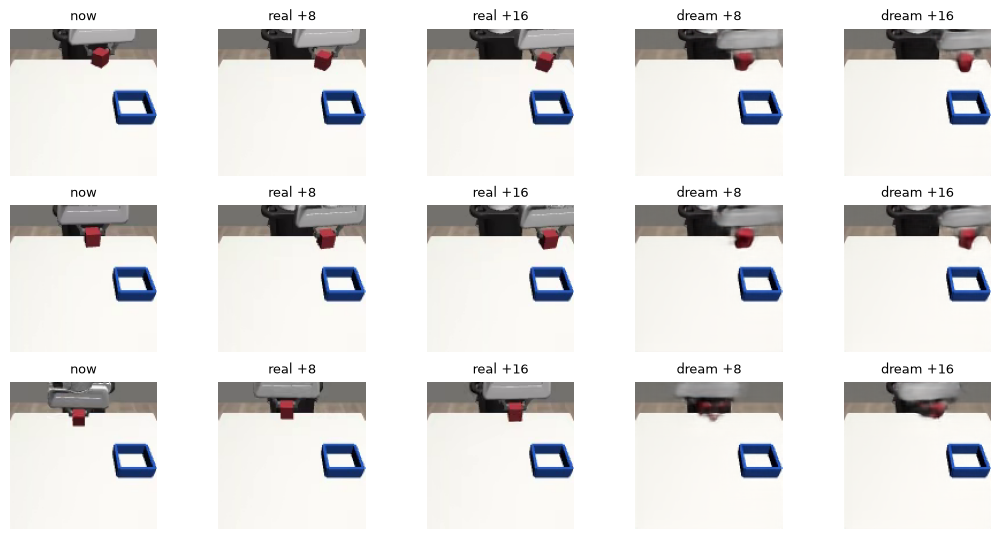

In [64]:
fig, axs = plt.subplots(3, 1 + 2 * K, figsize=(13, 6.5))
for r in range(3):
    ims = [now_img[r, 0], *real_img[r], *dz_img[r]]
    names = ['now', 'real +8', 'real +16', 'dream +8', 'dream +16']
    for ax, im, name in zip(axs[r], ims, names):
        ax.imshow(((im.permute(1, 2, 0) + 1) / 2).clamp(0, 1).cpu())
        ax.set_title(name, fontsize=9)
        ax.axis('off')
plt.show()

In [65]:
@cache
def sweep_z(n_exec: int) -> dict[int, tuple]:
    # step 11's sweep with step 23's WAMz; out: {seed: (ok, mode, steps)}
    torch.manual_seed(n_exec)  # the sampling noise, fixed per call
    res = {seed: rollout(netz, seed, n_exec) for seed in range(1000, 1020)}
    fails = Counter(mode for ok, mode, _ in res.values() if not ok)
    print(
        f'n_exec {n_exec:2d}: {sum(ok for ok, _, _ in res.values()):2d}/20   failures {dict(fails)}'
    )
    return res

sweep_z: cached, 2 call(s) stored


In [66]:
sweeps_z = {n_exec: sweep_z(n_exec) for n_exec in [8, 16]}
print('pixels, same recipe (step 15): 11, 13')

n_exec  8: 18/20   failures {'no_grasp': 2}
n_exec 16: 16/20   failures {'no_grasp': 3, 'dropped': 1}
pixels, same recipe (step 15): 11, 13


### step 25 — the floor for the video test: `WAMz` on 3 labelled demos

10 labelled already gives 34/40, too close to the top to show video helping. With 3 (uwm2: 12/40) there's room. Same recipe as step 23. Action/joint stats still come from the 10 labelled demos; the video-pretrained arm will use the same, so the comparison is fair.


In [75]:
@cache
def train_zn(n_lab: int, steps: int = 20000, B: int = 32, lr: float = 3e-4, seed: int = 0):
    # train_z on the first n_lab labelled demos only; prints (frame, action) losses;
    # out: weights (CPU), log rows [step, train frame, train act, val frame, val act]
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    net = WAMz().to(dev)
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    log = []
    with torch.enable_grad():
        for step in range(steps + 1):
            with torch.autocast('cuda', dtype=torch.bfloat16):
                lf, la = batch_loss_z(net, get_batch(eps['labelled'][:n_lab], B, rng, to_end=True))
            opt.zero_grad()
            (lf + la).backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
            if step % 500 == 0:
                with torch.no_grad(), torch.autocast('cuda', dtype=torch.bfloat16):
                    val_b = get_batch(eps['val'], 32, np.random.default_rng(1))
                    vf, va = batch_loss_z(net, val_b)
                log.append([step, lf.item(), la.item(), vf.item(), va.item()])
                print(f'{step:5d}  train {lf:.3f} {la:.3f}   val {vf:.3f} {va:.3f}')
    return frozendict(weights={k: v.cpu() for k, v in net.state_dict().items()}, log=np.array(log))

train_zn: cached, 1 call(s) stored


In [76]:
run_z3 = train_zn(3)
print(f'labelled demos used: {eps["labelled"][:3]}')

    0  train 2.523 2.960   val 2.307 2.628
  500  train 0.865 0.321   val 0.942 1.139
 1000  train 0.604 0.181   val 0.658 1.080
 1500  train 0.501 0.108   val 0.566 1.605
 2000  train 0.374 0.090   val 0.540 1.589
 2500  train 0.391 0.115   val 0.507 1.891
 3000  train 0.363 0.093   val 0.501 1.524
 3500  train 0.356 0.079   val 0.477 1.430
 4000  train 0.276 0.049   val 0.493 1.964
 4500  train 0.317 0.079   val 0.493 1.823
 5000  train 0.327 0.087   val 0.518 2.540
 5500  train 0.296 0.086   val 0.499 2.023
 6000  train 0.218 0.041   val 0.459 2.045
 6500  train 0.252 0.083   val 0.469 1.713
 7000  train 0.251 0.058   val 0.488 1.500
 7500  train 0.221 0.041   val 0.516 1.749
 8000  train 0.210 0.043   val 0.525 1.840
 8500  train 0.216 0.041   val 0.528 1.920
 9000  train 0.192 0.037   val 0.528 2.207
 9500  train 0.234 0.066   val 0.528 2.651
10000  train 0.175 0.033   val 0.557 1.858
10500  train 0.181 0.041   val 0.533 2.042
11000  train 0.188 0.055   val 0.564 2.256
11500  trai

In [77]:
runs_z = {'3 labelled': run_z3}


@cache
def sweep_zrun(name: str, n_exec: int) -> dict[int, tuple]:
    # step 11's sweep with WAMz weights runs_z[name]; out: {seed: (ok, mode, steps)}
    net = WAMz().to(dev)
    net.load_state_dict(runs_z[name]['weights'])
    torch.manual_seed(n_exec)  # the sampling noise, fixed per call
    res = {seed: rollout(net, seed, n_exec) for seed in range(1000, 1020)}
    fails = Counter(mode for ok, mode, _ in res.values() if not ok)
    print(
        f'n_exec {n_exec:2d}: {sum(ok for ok, _, _ in res.values()):2d}/20   failures {dict(fails)}'
    )
    return res

sweep_zrun: cached, 6 call(s) stored


In [78]:
sweeps_z3 = {n_exec: sweep_zrun('3 labelled', n_exec) for n_exec in [8, 16]}
print('10 labelled (step 24): 18, 16   uwm2 3 labelled: 6, 6')

n_exec  8:  6/20   failures {'no_grasp': 14}
n_exec 16:  5/20   failures {'dropped': 2, 'no_grasp': 13}
10 labelled (step 24): 18, 16   uwm2 3 labelled: 6, 6


### step 26 — stage 1, our "Wan": a video-only model on the 80 video-only demos

Floor (step 25): 3 labelled alone → 6 + 5 = 11/40. Stage 1 never sees actions or joints: every token is blocked from looking at the action and joint tokens, as if they weren't there (Wan had none; DreamZero added them later). Loss on frames only. Same 20k steps, batch 32.


In [79]:
is_robot = torch.zeros(len(t), dtype=torch.bool)  # [T] joint and action tokens
is_robot[edges[1::2]] = True  # each noisy chunk's first token: its joints
is_robot[idx['action'].flatten()] = True


class WAMv(WAMz):
    # WAMz with joints and actions hidden: a pure video model
    def __init__(self):
        super().__init__()
        self.blocked = self.blocked | is_robot[None, :].to(self.blocked.device)


def batch_loss_v(net: WAMv, b: Batch) -> torch.Tensor:
    # frame loss only; actions and joints never read (zeros, and masked anyway)
    B = len(b.rows)
    seen = latent_tokens(lat[b.rows])  # [B, 9, 64, 16]
    clean_f = seen[:, 1:].reshape(B, M, K * 64, 16)
    tau = torch.rand(B, M, device=dev)
    noise_f = torch.randn_like(clean_f)
    tf = tau.view(B, M, 1, 1)
    zeros_a, zeros_s = torch.zeros(B, M, H, 8, device=dev), torch.zeros(B, M, 8, device=dev)
    v_f, _ = net(seen, zeros_s, (1 - tf) * noise_f + tf * clean_f, zeros_a, tau)
    return F.mse_loss(v_f, clean_f - noise_f)

In [80]:
netv = WAMv().to(dev)
print(f'robot tokens hidden: {is_robot.sum().item()} of {len(t)}')
print(f'untrained frame loss: {batch_loss_v(netv, b).item():.3f}   (WAMz untrained 2.52)')

robot tokens hidden: 68 of 1028
untrained frame loss: 2.502   (WAMz untrained 2.52)


In [81]:
# check: the frames' output must not move when actions or joints change
seen_v = latent_tokens(lat[b.rows])
x_f, tau_v = torch.randn(32, M, K * 64, 16, device=dev), torch.rand(32, M, device=dev)
s0, a0 = torch.zeros(32, M, 8, device=dev), torch.zeros(32, M, H, 8, device=dev)
out0, _ = netv(seen_v, s0, x_f, a0, tau_v)
out1, _ = netv(seen_v, torch.randn_like(s0), x_f, torch.randn_like(a0), tau_v)
print(f'frame output change from random actions + joints: {(out1 - out0).abs().max():.1e}')

frame output change from random actions + joints: 0.0e+00


In [82]:
@cache
def train_video(steps: int = 20000, B: int = 32, lr: float = 3e-4, seed: int = 0):
    # stage 1: WAMv on the 80 video-only demos, frames only; prints frame loss (train, val);
    # out: weights (CPU), log rows [step, train frame, val frame]
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    net = WAMv().to(dev)
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    log = []
    with torch.enable_grad():
        for step in range(steps + 1):
            with torch.autocast('cuda', dtype=torch.bfloat16):
                lf = batch_loss_v(net, get_batch(eps['video'], B, rng, to_end=True))
            opt.zero_grad()
            lf.backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
            if step % 500 == 0:
                with torch.no_grad(), torch.autocast('cuda', dtype=torch.bfloat16):
                    val_b = get_batch(eps['val'], 32, np.random.default_rng(1))
                    vf = batch_loss_v(net, val_b)
                log.append([step, lf.item(), vf.item()])
                print(f'{step:5d}  train {lf:.3f}   val {vf:.3f}')
    return frozendict(weights={k: v.cpu() for k, v in net.state_dict().items()}, log=np.array(log))

train_video: cached, 1 call(s) stored


In [83]:
run_video = train_video()
print('val frame, 10 labelled (step 23): 0.30   3 labelled (step 25): 0.68')

    0  train 2.528   val 2.251
  500  train 0.491   val 0.580
 1000  train 0.465   val 0.481
 1500  train 0.421   val 0.465
 2000  train 0.350   val 0.421
 2500  train 0.350   val 0.430
 3000  train 0.349   val 0.386
 3500  train 0.336   val 0.382
 4000  train 0.290   val 0.371
 4500  train 0.287   val 0.347
 5000  train 0.317   val 0.345
 5500  train 0.259   val 0.333
 6000  train 0.254   val 0.307
 6500  train 0.253   val 0.299
 7000  train 0.273   val 0.290
 7500  train 0.253   val 0.276
 8000  train 0.221   val 0.287
 8500  train 0.255   val 0.280
 9000  train 0.195   val 0.267
 9500  train 0.239   val 0.266
10000  train 0.175   val 0.278
10500  train 0.227   val 0.263
11000  train 0.212   val 0.265
11500  train 0.221   val 0.248
12000  train 0.206   val 0.230
12500  train 0.180   val 0.246
13000  train 0.190   val 0.243
13500  train 0.210   val 0.230
14000  train 0.183   val 0.241
14500  train 0.206   val 0.246
15000  train 0.169   val 0.232
15500  train 0.185   val 0.234
16000  t

### step 27 — stage 2: the video model learns actions from 3 labelled demos

Load stage 1's weights into `WAMz` (joints and actions visible again), then step 25's exact recipe. Two arms: **all** layers trained (DreamZero's way), or **frozen** video model with only the joint and action layers trained (the video-features thesis). Floor: 11/40.


In [84]:
@cache
def train_stage2(
    n_lab: int, freeze: bool, steps: int = 20000, B: int = 32, lr: float = 3e-4, seed: int = 0
):
    # train_zn starting from stage 1's video model; freeze: train only the joint and
    # action layers (the video model stays as stage 1 left it); prints (frame, action) losses;
    # out: weights (CPU), log rows [step, train frame, train act, val frame, val act]
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    net = WAMz().to(dev)
    video = {k: v for k, v in run_video['weights'].items() if k != 'blocked'}  # keep WAMz's mask
    net.load_state_dict(video, strict=False)
    robot = ['state_in', 'action_in', 'action_out']  # the layers stage 1 never trained
    params = [p for n, p in net.named_parameters() if not freeze or n.split('.')[0] in robot]
    opt = torch.optim.AdamW(params, lr=lr)
    log = []
    with torch.enable_grad():
        for step in range(steps + 1):
            with torch.autocast('cuda', dtype=torch.bfloat16):
                lf, la = batch_loss_z(net, get_batch(eps['labelled'][:n_lab], B, rng, to_end=True))
            opt.zero_grad()
            (lf + la).backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
            if step % 500 == 0:
                with torch.no_grad(), torch.autocast('cuda', dtype=torch.bfloat16):
                    val_b = get_batch(eps['val'], 32, np.random.default_rng(1))
                    vf, va = batch_loss_z(net, val_b)
                log.append([step, lf.item(), la.item(), vf.item(), va.item()])
                print(f'{step:5d}  train {lf:.3f} {la:.3f}   val {vf:.3f} {va:.3f}')
    return frozendict(weights={k: v.cpu() for k, v in net.state_dict().items()}, log=np.array(log))

train_stage2: cached, 1 call(s) stored


In [85]:
run_s2_all = train_stage2(3, freeze=False)
runs_z['stage 2, all'] = run_s2_all

    0  train 0.163 4.221   val 0.405 2.680
  500  train 0.184 0.249   val 0.279 1.318
 1000  train 0.192 0.174   val 0.267 1.414
 1500  train 0.166 0.109   val 0.285 1.995
 2000  train 0.137 0.088   val 0.293 2.172
 2500  train 0.173 0.116   val 0.290 1.960
 3000  train 0.154 0.092   val 0.290 2.008
 3500  train 0.151 0.087   val 0.296 1.957
 4000  train 0.112 0.064   val 0.320 2.225
 4500  train 0.143 0.081   val 0.326 2.125
 5000  train 0.161 0.086   val 0.374 2.814
 5500  train 0.166 0.090   val 0.353 2.120
 6000  train 0.101 0.045   val 0.321 2.151
 6500  train 0.137 0.077   val 0.329 1.785
 7000  train 0.133 0.058   val 0.349 1.811
 7500  train 0.102 0.040   val 0.384 1.722
 8000  train 0.117 0.044   val 0.375 2.261
 8500  train 0.112 0.042   val 0.386 2.187
 9000  train 0.101 0.041   val 0.392 2.397
 9500  train 0.138 0.072   val 0.386 2.644
10000  train 0.100 0.037   val 0.418 2.058
10500  train 0.110 0.043   val 0.395 2.114
11000  train 0.117 0.057   val 0.424 2.423
11500  trai

In [86]:
sweeps_s2_all = {n_exec: sweep_zrun('stage 2, all', n_exec) for n_exec in [8, 16]}
print('floor, 3 labelled alone (step 25): 6, 5')

n_exec  8:  9/20   failures {'no_grasp': 10, 'dropped': 1}
n_exec 16:  8/20   failures {'no_grasp': 11, 'dropped': 1}
floor, 3 labelled alone (step 25): 6, 5


In [90]:
run_s2_frozen = train_stage2(3, freeze=True)
runs_z['stage 2, frozen'] = run_s2_frozen

    0  train 0.163 4.221   val 0.208 3.517
  500  train 0.178 1.271   val 0.227 1.581
 1000  train 0.212 0.913   val 0.232 1.205
 1500  train 0.206 0.758   val 0.242 1.173
 2000  train 0.169 0.620   val 0.247 1.114
 2500  train 0.211 0.659   val 0.243 0.990
 3000  train 0.201 0.575   val 0.230 0.948
 3500  train 0.198 0.566   val 0.229 0.928
 4000  train 0.155 0.496   val 0.240 0.949
 4500  train 0.189 0.512   val 0.244 0.963
 5000  train 0.216 0.511   val 0.271 1.034
 5500  train 0.213 0.559   val 0.244 0.932
 6000  train 0.148 0.419   val 0.224 0.888
 6500  train 0.188 0.451   val 0.224 0.871
 7000  train 0.183 0.436   val 0.214 0.840
 7500  train 0.158 0.392   val 0.236 0.872
 8000  train 0.167 0.450   val 0.233 0.905
 8500  train 0.165 0.401   val 0.235 0.855
 9000  train 0.150 0.413   val 0.222 0.896
 9500  train 0.191 0.464   val 0.238 0.924
10000  train 0.145 0.394   val 0.226 0.807
10500  train 0.161 0.457   val 0.230 0.781
11000  train 0.167 0.408   val 0.236 0.880
11500  trai

In [91]:
sweeps_s2_frozen = {n_exec: sweep_zrun('stage 2, frozen', n_exec) for n_exec in [8, 16]}
print('floor: 6, 5   stage 2, all layers: 9, 8')

n_exec  8:  3/20   failures {'no_grasp': 15, 'dropped': 1, 'wrong_target': 1}
n_exec 16:  3/20   failures {'dropped': 1, 'no_grasp': 16}
floor: 6, 5   stage 2, all layers: 9, 8


### step 28 — co-training: keep practising video while learning actions

Stage 2 (all layers), but every batch is half labelled (frames + actions, as before) and half video-only (frames, seen through stage 1's mask: no joints, no actions). The video half keeps the model from forgetting the 80 demos while 3 demos teach the actions.


In [87]:
@cache
def train_cotrain(n_lab: int, steps: int = 20000, B: int = 32, lr: float = 3e-4, seed: int = 0):
    # train_stage2 (all layers) with half of each batch from the video-only demos;
    # prints labelled (frame, action), video frame, val (frame, action);
    # out: weights (CPU), log rows [step, frame, act, video frame, val frame, val act]
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    net = WAMz().to(dev)
    video = {k: v for k, v in run_video['weights'].items() if k != 'blocked'}
    net.load_state_dict(video, strict=False)
    masks = frozendict(robot=net.blocked.clone(), video=net.blocked | is_robot[None, :].to(dev))
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    log = []
    with torch.enable_grad():
        for step in range(steps + 1):
            with torch.autocast('cuda', dtype=torch.bfloat16):
                net.blocked = masks['robot']
                lab_b = get_batch(eps['labelled'][:n_lab], B // 2, rng, to_end=True)
                lf, la = batch_loss_z(net, lab_b)
                net.blocked = masks['video']
                lv = batch_loss_v(net, get_batch(eps['video'], B // 2, rng, to_end=True))
            net.blocked = masks['robot']
            opt.zero_grad()
            (lf + la + lv).backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
            if step % 500 == 0:
                with torch.no_grad(), torch.autocast('cuda', dtype=torch.bfloat16):
                    val_b = get_batch(eps['val'], 32, np.random.default_rng(1))
                    vf, va = batch_loss_z(net, val_b)
                log.append([step, lf.item(), la.item(), lv.item(), vf.item(), va.item()])
                print(f'{step:5d}  lab {lf:.3f} {la:.3f}  video {lv:.3f}   val {vf:.3f} {va:.3f}')
    return frozendict(weights={k: v.cpu() for k, v in net.state_dict().items()}, log=np.array(log))

train_cotrain: cached, 1 call(s) stored


In [88]:
run_cotrain = train_cotrain(3)
runs_z['co-train'] = run_cotrain

    0  lab 0.163 4.336  video 0.126   val 0.423 2.655
  500  lab 0.139 0.239  video 0.185   val 0.250 1.217
 1000  lab 0.171 0.167  video 0.203   val 0.235 1.392
 1500  lab 0.172 0.190  video 0.199   val 0.220 1.543
 2000  lab 0.167 0.147  video 0.218   val 0.211 1.535
 2500  lab 0.133 0.110  video 0.244   val 0.244 1.675
 3000  lab 0.157 0.127  video 0.177   val 0.203 1.463
 3500  lab 0.164 0.116  video 0.231   val 0.208 1.699
 4000  lab 0.122 0.067  video 0.189   val 0.218 1.606
 4500  lab 0.136 0.078  video 0.202   val 0.208 1.596
 5000  lab 0.121 0.060  video 0.232   val 0.222 1.445
 5500  lab 0.127 0.079  video 0.177   val 0.214 1.460
 6000  lab 0.116 0.058  video 0.190   val 0.221 1.828
 6500  lab 0.137 0.080  video 0.217   val 0.230 1.977
 7000  lab 0.108 0.059  video 0.167   val 0.228 1.826
 7500  lab 0.137 0.054  video 0.140   val 0.212 1.743
 8000  lab 0.138 0.073  video 0.195   val 0.216 1.708
 8500  lab 0.166 0.091  video 0.169   val 0.199 1.629
 9000  lab 0.132 0.068  vide

In [89]:
sweeps_cotrain = {n_exec: sweep_zrun('co-train', n_exec) for n_exec in [8, 16]}
print('floor: 6, 5   stage 2, all layers: 9, 8')

n_exec  8:  6/20   failures {'no_grasp': 13, 'wrong_target': 1}
n_exec 16:  7/20   failures {'no_grasp': 12, 'dropped': 1}
floor: 6, 5   stage 2, all layers: 9, 8


## Films of WAMz (10 labelled): real top camera | the dream (+8 steps) it is acting on
Same order and torch seed as the sweep, so outcomes match step 24; films kept for a few seeds.

In [67]:
import imageio


def film_rollout(net: WAMz, seed: int, n_exec: int) -> tuple[bool, str, list]:
    # rollout(), but each frame is [real top | dream +8 of the current plan], 128 x 256
    obs, plan, out, dream_img = env.reset(seed=seed), [], [], None
    for step in range(600):
        if not plan:
            frame = torch.from_numpy(obs.images['top']).permute(2, 0, 1).to(dev)
            frames = frame.expand(1, 1 + M * K, -1, -1, -1)
            state = torch.from_numpy(obs.state).to(dev).expand(1, M, -1)
            d_f, d_a = dream_z(net, frames, state)
            lat_d = latent_from_tokens(d_f.view(1, K, 64, 16))[0, :1]  # [1, 4, 16, 16], +8
            dream_img = ((vae_t['dec'](lat_d)[0].permute(1, 2, 0) + 1) * 127.5).clamp(0, 255)
            dream_img = dream_img.byte().cpu().numpy()
            chunk = (d_a * stats['a_std'] + stats['a_mean'])[0].cpu().numpy()
            chunk[:, 7] = np.clip(chunk[:, 7], 0.0, 1.0)
            plan = list(chunk[:n_exec])
        out.append(np.concatenate([obs.images['top'], dream_img], axis=1))
        r = env.step(plan.pop(0))
        obs = r.observation
        if r.terminated or r.truncated:
            break
    return r.success, str(r.failure_mode), out


keep = {1000, 1009, 1012, 1013, 1015}
for n_exec in [8, 16]:
    torch.manual_seed(n_exec)  # as sweep_z
    for seed in range(1000, 1020):
        ok, mode, frames_seen = film_rollout(netz, seed, n_exec)
        if seed in keep:
            path = f'../scratch/wamz_n{n_exec}_seed{seed}_{"ok" if ok else mode}.mp4'
            imageio.mimsave(path, frames_seen, fps=20)
            print(
                f'n_exec {n_exec:2d} seed {seed}: {"ok" if ok else mode:9s} {len(frames_seen)} steps -> {path}'
            )

n_exec  8 seed 1000: ok        196 steps -> ../scratch/wamz_n8_seed1000_ok.mp4
n_exec  8 seed 1009: ok        210 steps -> ../scratch/wamz_n8_seed1009_ok.mp4
n_exec  8 seed 1012: ok        230 steps -> ../scratch/wamz_n8_seed1012_ok.mp4
n_exec  8 seed 1013: no_grasp  600 steps -> ../scratch/wamz_n8_seed1013_no_grasp.mp4
n_exec  8 seed 1015: no_grasp  600 steps -> ../scratch/wamz_n8_seed1015_no_grasp.mp4
n_exec 16 seed 1000: ok        205 steps -> ../scratch/wamz_n16_seed1000_ok.mp4
n_exec 16 seed 1009: no_grasp  600 steps -> ../scratch/wamz_n16_seed1009_no_grasp.mp4
n_exec 16 seed 1012: no_grasp  600 steps -> ../scratch/wamz_n16_seed1012_no_grasp.mp4
n_exec 16 seed 1013: no_grasp  600 steps -> ../scratch/wamz_n16_seed1013_no_grasp.mp4
n_exec 16 seed 1015: dropped   600 steps -> ../scratch/wamz_n16_seed1015_dropped.mp4
